<a href="https://colab.research.google.com/github/Syn-Sat/Surrogate_Modelling/blob/main/toxicity5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 38.1/38.1 MB 45.6 MB/s eta 0:00:00
Dataset shape: (7831, 14)

Dataset columns:
['NR-AR', 'NR-AR-LBD', 'NR-AhR', 'NR-Aromatase', 'NR-ER', 'NR-ER-LBD', 'NR-PPAR-gamma', 'SR-ARE', 'SR-ATAD5', 'SR-HSE', 'SR-MMP', 'SR-p53', 'mol_id', 'smiles']

SMILES column: smiles
Toxicity target: NR-AR

Extracting molecular features...


[13:30:11] WARNING: not removing hydrogen atom without neighbors
[13:30:12] Explicit valence for atom # 3 Al, 6, is greater than permitted
[13:30:12] Explicit valence for atom # 4 Al, 6, is greater than permitted
[13:30:14] Explicit valence for atom # 4 Al, 6, is greater than permitted
[13:30:15] Explicit valence for atom # 9 Al, 6, is greater than permitted
[13:30:15] Explicit valence for atom # 5 Al, 6, is greater than permitted
[13:30:16] Explicit valence for atom # 16 Al, 6, is greater than permitted
[13:30:17] Explicit valence for atom # 20 Al, 6, is greater than permitted



================ DATASET SUMMARY ================
Valid molecules: 7258
Invalid SMILES: 7
Number of features: 2053
Target distribution: (array([0, 1]), array([6950,  308]))


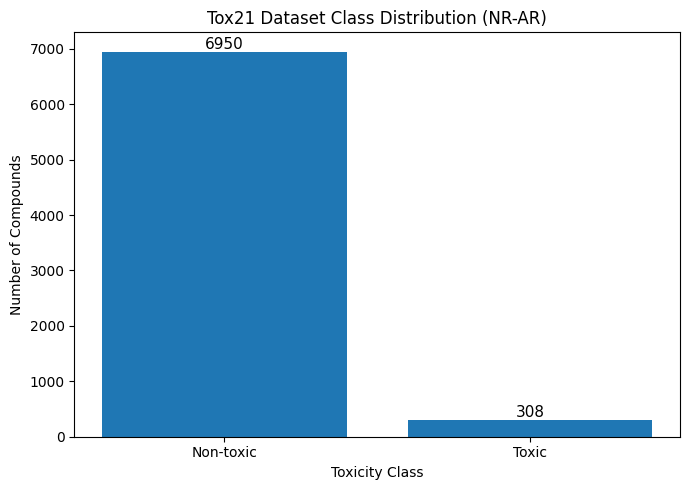


Training samples: 5806
Testing samples: 1452

TRAINING MODELS

Training Random Forest...

Training XGBoost...

Training Gradient Boosting...

================ MODEL RESULTS ================
            Model  Accuracy  ROC-AUC   PR-AUC
    Random Forest  0.973140 0.766518 0.483386
          XGBoost  0.970386 0.765642 0.466228
Gradient Boosting  0.965565 0.752118 0.425705


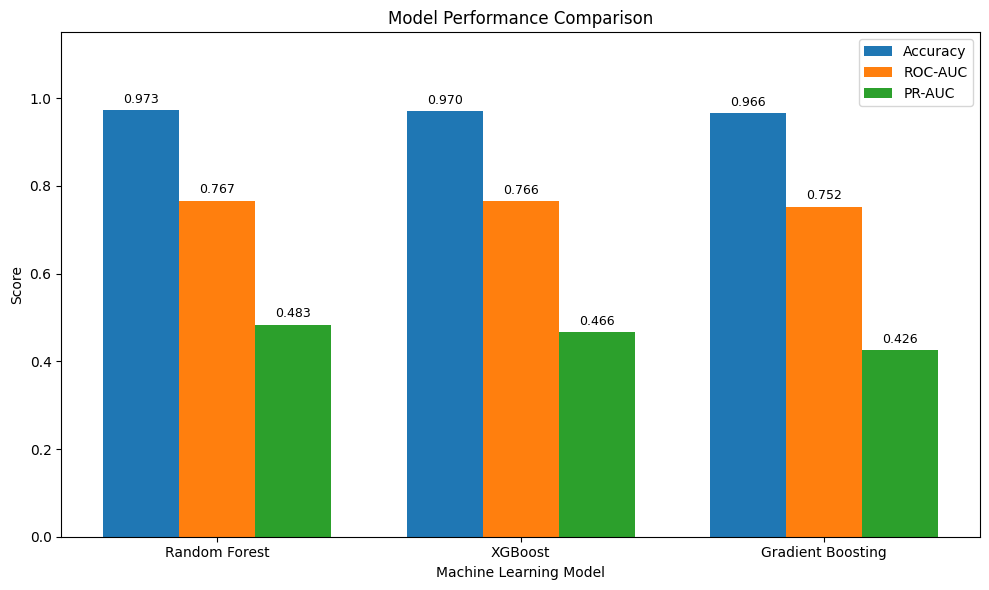

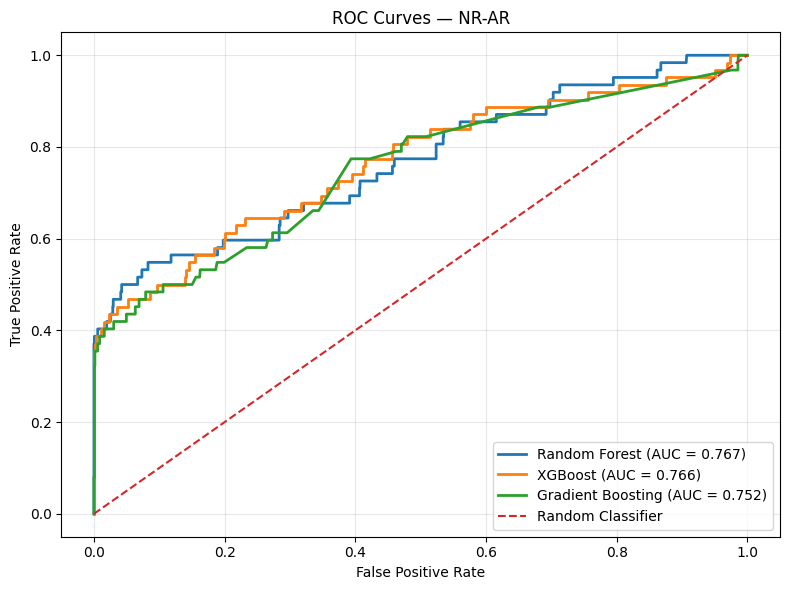

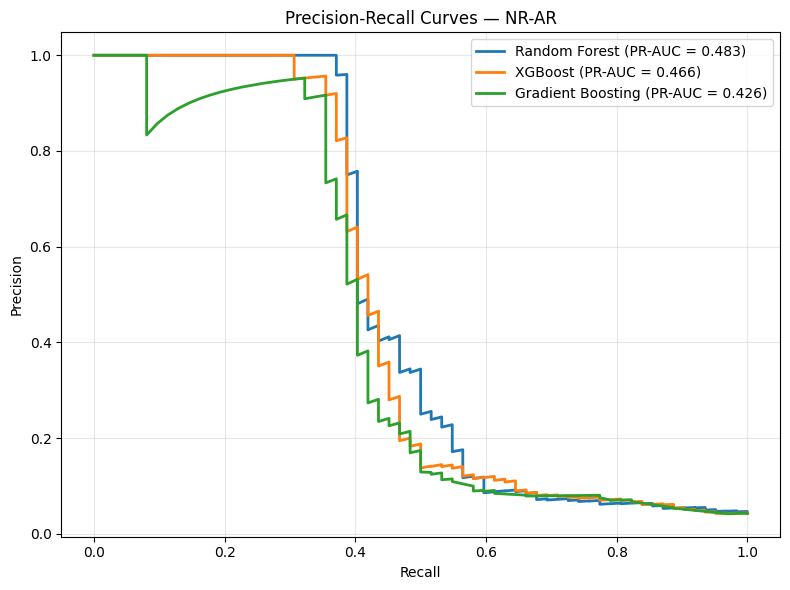


BEST MODEL
Model: Random Forest
ROC-AUC: 0.7665
PR-AUC: 0.4834


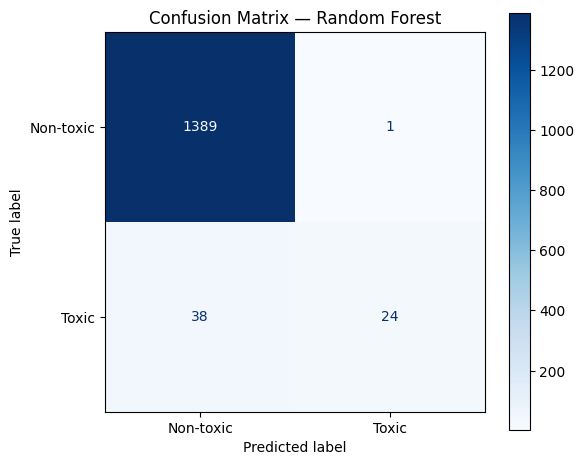

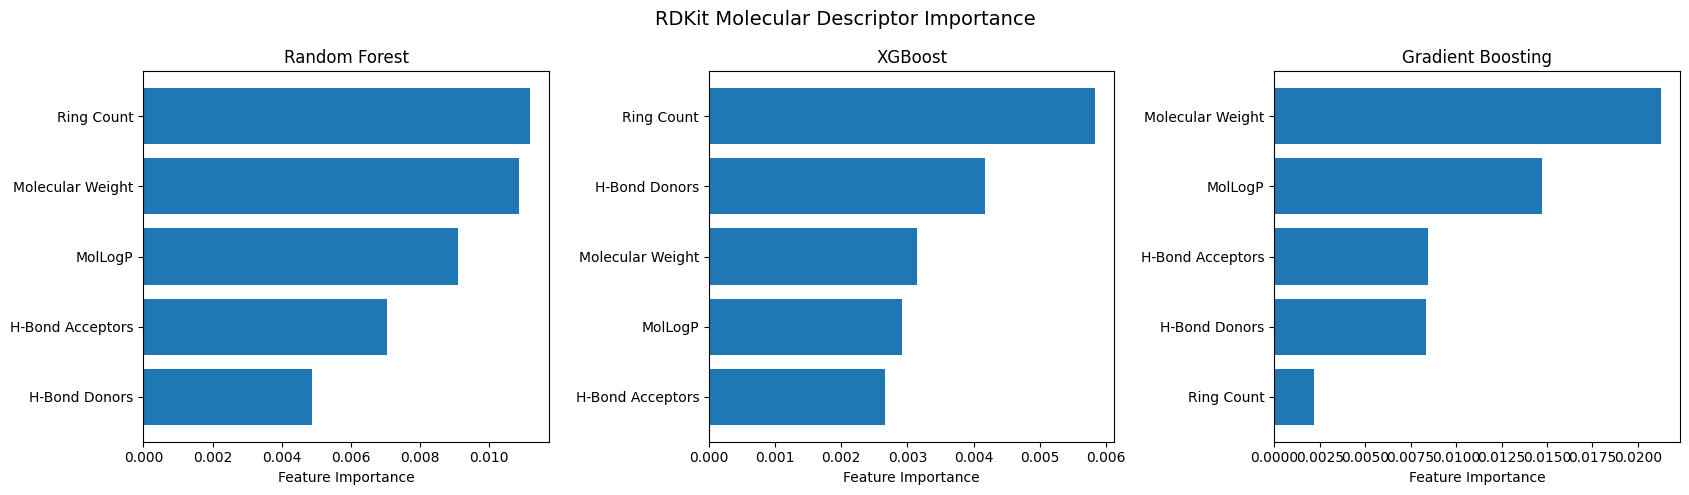

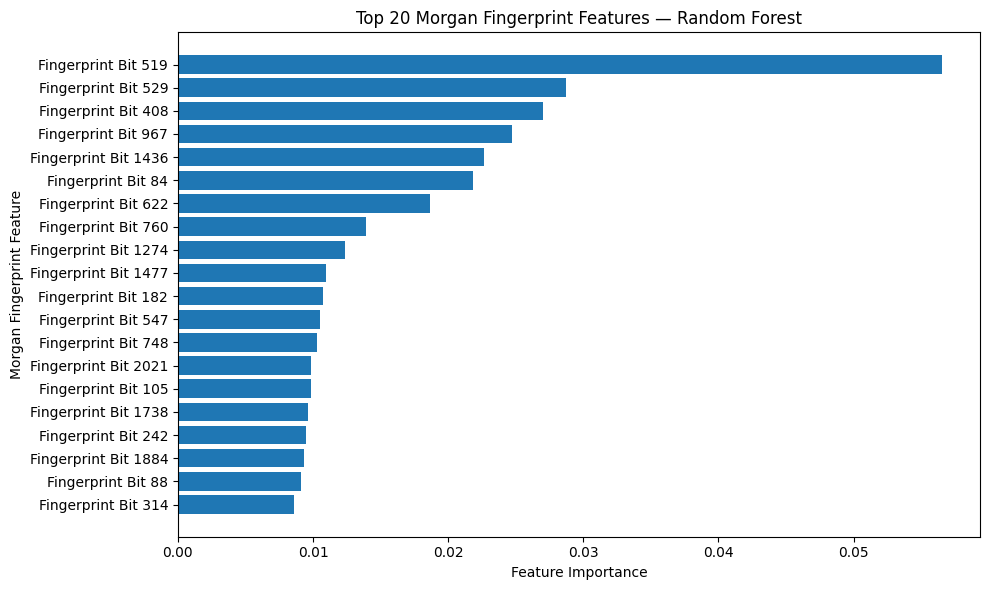


SMILES TOXICITY PREDICTIONS
                         SMILES  Random Forest Toxicity Probability Random Forest Prediction  XGBoost Toxicity Probability XGBoost Prediction  Gradient Boosting Toxicity Probability Gradient Boosting Prediction
                            CCO                              0.0149                Non-toxic                        0.0078          Non-toxic                                  0.0098                    Non-toxic
                       c1ccccc1                              0.0147                Non-toxic                        0.0131          Non-toxic                                  0.0098                    Non-toxic
          CC(=O)Oc1ccccc1C(=O)O                              0.0208                Non-toxic                        0.0095          Non-toxic                                  0.0088                    Non-toxic
CC(C)Cc1ccc(cc1)[C@@H](C)C(=O)O                              0.0180                Non-toxic                        0.0107     

In [ ]:
# ============================================================
# TOX21 SMILES-BASED TOXICITY PREDICTION
# Random Forest vs XGBoost vs Gradient Boosting
# With PPT-ready graphs
# ============================================================

!pip install -q rdkit xgboost

# ============================================================
# 1. IMPORT LIBRARIES
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from rdkit import Chem
from rdkit.Chem import Descriptors, Lipinski, rdFingerprintGenerator

from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier
)

from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    average_precision_score,
    roc_curve,
    precision_recall_curve,
    confusion_matrix,
    ConfusionMatrixDisplay
)

from sklearn.model_selection import train_test_split

from xgboost import XGBClassifier


# ============================================================
# 2. LOAD TOX21 DATASET
# ============================================================

URL = (
    "https://deepchemdata.s3-us-west-1.amazonaws.com/"
    "datasets/tox21.csv.gz"
)

df = pd.read_csv(URL, compression="gzip")

print("Dataset shape:", df.shape)

print("\nDataset columns:")
print(df.columns.tolist())


# ============================================================
# 3. IDENTIFY SMILES COLUMN
# ============================================================

if "smiles" in df.columns:
    SMILES_COL = "smiles"

elif "SMILES" in df.columns:
    SMILES_COL = "SMILES"

else:
    raise ValueError(
        "No SMILES column found. Check your dataset."
    )


# ============================================================
# 4. SELECT TOXICITY TARGET
# ============================================================

TARGET_COL = "NR-AR"

if TARGET_COL not in df.columns:
    raise ValueError(
        f"{TARGET_COL} was not found in the dataset."
    )

print("\nSMILES column:", SMILES_COL)
print("Toxicity target:", TARGET_COL)


# ============================================================
# 5. INITIALIZE MORGAN FINGERPRINT GENERATOR
# ============================================================

morgan_generator = rdFingerprintGenerator.GetMorganGenerator(
    radius=2,
    fpSize=2048
)


# ============================================================
# 6. SMILES → MOLECULAR FEATURES
# ============================================================

def extract_tox_features(smiles):
    """
    Converts a SMILES string into:

    2048 Morgan fingerprint features
    +
    5 molecular descriptors

    Total = 2053 features
    """

    if not isinstance(smiles, str):
        return None

    mol = Chem.MolFromSmiles(smiles)

    if mol is None:
        return None

    # --------------------------------------------------------
    # Morgan fingerprint
    # --------------------------------------------------------

    fp = morgan_generator.GetFingerprintAsNumPy(mol)

    # --------------------------------------------------------
    # RDKit molecular descriptors
    # --------------------------------------------------------

    descriptors = np.array([
        Descriptors.MolWt(mol),
        Descriptors.MolLogP(mol),
        Lipinski.NumHDonors(mol),
        Lipinski.NumHAcceptors(mol),
        Lipinski.RingCount(mol)
    ], dtype=np.float32)

    # Combine fingerprint + descriptors
    return np.hstack([fp, descriptors])


# ============================================================
# 7. CLEAN DATA AND CREATE FEATURES
# ============================================================

print("\nExtracting molecular features...")

df_clean = df.dropna(
    subset=[SMILES_COL, TARGET_COL]
).copy()

X_list = []
y_list = []
valid_smiles = []

invalid_count = 0

for _, row in df_clean.iterrows():

    smiles = row[SMILES_COL]

    features = extract_tox_features(smiles)

    if features is not None:

        X_list.append(features)
        y_list.append(row[TARGET_COL])
        valid_smiles.append(smiles)

    else:
        invalid_count += 1


# Convert features to NumPy
X = np.array(
    X_list,
    dtype=np.float32
)

# Convert labels
y = pd.to_numeric(
    pd.Series(y_list),
    errors="coerce"
).values


# Remove invalid target values
valid_target_mask = ~np.isnan(y)

X = X[valid_target_mask]

y = y[valid_target_mask].astype(int)

valid_smiles = np.array(
    valid_smiles
)[valid_target_mask]


print("\n================ DATASET SUMMARY ================")

print("Valid molecules:", len(X))
print("Invalid SMILES:", invalid_count)
print("Number of features:", X.shape[1])

print(
    "Target distribution:",
    np.unique(
        y,
        return_counts=True
    )
)

print("==================================================")


# ============================================================
# 8. GRAPH 1 — TOXIC VS NON-TOXIC CLASS DISTRIBUTION
# ============================================================

class_counts = pd.Series(y).value_counts().sort_index()

non_toxic_count = class_counts.get(0, 0)
toxic_count = class_counts.get(1, 0)

plt.figure(figsize=(7, 5))

bars = plt.bar(
    ["Non-toxic", "Toxic"],
    [non_toxic_count, toxic_count]
)

plt.ylabel("Number of Compounds")
plt.xlabel("Toxicity Class")
plt.title(
    f"Tox21 Dataset Class Distribution ({TARGET_COL})"
)

# Add values above bars
for bar in bars:

    height = bar.get_height()

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        f"{int(height)}",
        ha="center",
        va="bottom",
        fontsize=11
    )

plt.tight_layout()

# Save for PPT
plt.savefig(
    "01_class_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 9. TRAIN / TEST SPLIT
# ============================================================

X_train, X_test, y_train, y_test = train_test_split(

    X,
    y,

    test_size=0.20,

    random_state=42,

    stratify=y
)

print("\nTraining samples:", len(X_train))
print("Testing samples:", len(X_test))


# ============================================================
# 10. DEFINE MODELS
# ============================================================

models = {

    "Random Forest": RandomForestClassifier(
        n_estimators=150,
        max_depth=12,
        random_state=42,
        n_jobs=-1
    ),

    "XGBoost": XGBClassifier(
        n_estimators=150,
        max_depth=6,
        learning_rate=0.05,
        random_state=42,
        eval_metric="logloss",
        n_jobs=-1
    ),

    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=150,
        max_depth=5,
        learning_rate=0.05,
        random_state=42
    )
}


# ============================================================
# 11. TRAIN MODELS
# ============================================================

results = []

model_predictions = {}

print("\n========================================================")
print("TRAINING MODELS")
print("========================================================")

for name, model in models.items():

    print(f"\nTraining {name}...")

    model.fit(
        X_train,
        y_train
    )

    # Probability of toxic class
    y_pred_prob = model.predict_proba(
        X_test
    )[:, 1]

    # Binary prediction
    y_pred = model.predict(
        X_test
    )

    # --------------------------------------------------------
    # Metrics
    # --------------------------------------------------------

    accuracy = accuracy_score(
        y_test,
        y_pred
    )

    roc_auc = roc_auc_score(
        y_test,
        y_pred_prob
    )

    pr_auc = average_precision_score(
        y_test,
        y_pred_prob
    )

    # Store predictions
    model_predictions[name] = {
        "y_pred": y_pred,
        "y_prob": y_pred_prob
    }

    # Store metrics
    results.append({

        "Model": name,

        "Accuracy": accuracy,

        "ROC-AUC": roc_auc,

        "PR-AUC": pr_auc
    })


# ============================================================
# 12. MODEL RESULTS TABLE
# ============================================================

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    "ROC-AUC",
    ascending=False
).reset_index(drop=True)


print("\n================ MODEL RESULTS ================")

print(
    results_df.to_string(
        index=False
    )
)

print("================================================")


# ============================================================
# 13. GRAPH 2 — MODEL PERFORMANCE COMPARISON
# ============================================================

metrics = [
    "Accuracy",
    "ROC-AUC",
    "PR-AUC"
]

model_names = results_df["Model"]

x = np.arange(
    len(model_names)
)

width = 0.25

fig, ax = plt.subplots(
    figsize=(10, 6)
)

for i, metric in enumerate(metrics):

    values = results_df[metric]

    bars = ax.bar(
        x + (i - 1) * width,
        values,
        width,
        label=metric
    )

    # Add metric values on bars
    for bar, value in zip(
        bars,
        values
    ):

        ax.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 0.01,
            f"{value:.3f}",
            ha="center",
            va="bottom",
            fontsize=9
        )


ax.set_xlabel("Machine Learning Model")
ax.set_ylabel("Score")

ax.set_title(
    "Model Performance Comparison"
)

ax.set_xticks(x)
ax.set_xticklabels(model_names)

ax.set_ylim(
    0,
    1.15
)

ax.legend()

plt.tight_layout()

plt.savefig(
    "02_model_performance_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 14. GRAPH 3 — ROC CURVES
# ============================================================

plt.figure(
    figsize=(8, 6)
)

for name in models.keys():

    y_prob = model_predictions[name]["y_prob"]

    fpr, tpr, _ = roc_curve(
        y_test,
        y_prob
    )

    auc = roc_auc_score(
        y_test,
        y_prob
    )

    plt.plot(
        fpr,
        tpr,
        linewidth=2,
        label=f"{name} (AUC = {auc:.3f})"
    )


# Random classifier
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel(
    "False Positive Rate"
)

plt.ylabel(
    "True Positive Rate"
)

plt.title(
    f"ROC Curves — {TARGET_COL}"
)

plt.legend(
    loc="lower right"
)

plt.grid(
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    "03_ROC_curves.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 15. GRAPH 4 — PRECISION-RECALL CURVES
# ============================================================

plt.figure(
    figsize=(8, 6)
)

for name in models.keys():

    y_prob = model_predictions[name]["y_prob"]

    precision, recall, _ = precision_recall_curve(
        y_test,
        y_prob
    )

    pr_auc = average_precision_score(
        y_test,
        y_prob
    )

    plt.plot(
        recall,
        precision,
        linewidth=2,
        label=f"{name} (PR-AUC = {pr_auc:.3f})"
    )


plt.xlabel(
    "Recall"
)

plt.ylabel(
    "Precision"
)

plt.title(
    f"Precision-Recall Curves — {TARGET_COL}"
)

plt.legend(
    loc="best"
)

plt.grid(
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    "04_precision_recall_curves.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 16. IDENTIFY BEST MODEL
# ============================================================

best_model_name = results_df.iloc[0]["Model"]

best_model = models[
    best_model_name
]

best_predictions = model_predictions[
    best_model_name
]

print("\n================================================")
print("BEST MODEL")
print("================================================")

print("Model:", best_model_name)

print(
    "ROC-AUC:",
    round(
        results_df.iloc[0]["ROC-AUC"],
        4
    )
)

print(
    "PR-AUC:",
    round(
        results_df.iloc[0]["PR-AUC"],
        4
    )
)

print("================================================")


# ============================================================
# 17. GRAPH 5 — CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(
    y_test,
    best_predictions["y_pred"]
)

fig, ax = plt.subplots(
    figsize=(6, 5)
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[
        "Non-toxic",
        "Toxic"
    ]
)

disp.plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    colorbar=True
)

plt.title(
    f"Confusion Matrix — {best_model_name}"
)

plt.tight_layout()

plt.savefig(
    "05_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 18. FEATURE IMPORTANCE
# ============================================================

descriptor_names = [
    "Molecular Weight",
    "MolLogP",
    "H-Bond Donors",
    "H-Bond Acceptors",
    "Ring Count"
]

# Descriptor positions:
# 0-2047 = Morgan fingerprints
# 2048-2052 = RDKit descriptors

descriptor_start = 2048

descriptor_importance = {}

for name, model in models.items():

    # All tree models used here provide feature_importances_
    importance = model.feature_importances_

    descriptor_importance[name] = (
        importance[
            descriptor_start:
        ]
    )


# ============================================================
# 19. GRAPH 6 — RDKit DESCRIPTOR FEATURE IMPORTANCE
# ============================================================

importance_df = pd.DataFrame(
    descriptor_importance,
    index=descriptor_names
)

fig, axes = plt.subplots(
    1,
    3,
    figsize=(17, 5),
    sharey=False
)

for ax, model_name in zip(
    axes,
    models.keys()
):

    values = importance_df[
        model_name
    ].sort_values()

    ax.barh(
        values.index,
        values.values
    )

    ax.set_title(
        model_name
    )

    ax.set_xlabel(
        "Feature Importance"
    )


fig.suptitle(
    "RDKit Molecular Descriptor Importance",
    fontsize=14
)

plt.tight_layout()

plt.savefig(
    "06_descriptor_feature_importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 20. TOP MORGAN FINGERPRINT FEATURES
# ============================================================

# This is optional but useful for technical presentation.

if hasattr(best_model, "feature_importances_"):

    feature_importances = (
        best_model.feature_importances_
    )

    morgan_importance = feature_importances[
        :2048
    ]

    top_indices = np.argsort(
        morgan_importance
    )[-20:][::-1]

    top_values = morgan_importance[
        top_indices
    ]

    plt.figure(
        figsize=(10, 6)
    )

    labels = [
        f"Fingerprint Bit {i}"
        for i in top_indices
    ]

    plt.barh(
        labels[::-1],
        top_values[::-1]
    )

    plt.xlabel(
        "Feature Importance"
    )

    plt.ylabel(
        "Morgan Fingerprint Feature"
    )

    plt.title(
        f"Top 20 Morgan Fingerprint Features — {best_model_name}"
    )

    plt.tight_layout()

    plt.savefig(
        "07_top_morgan_features.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()


# ============================================================
# 21. SMILES → FEATURES FUNCTION
# ============================================================

def smiles_to_features(smiles_list):

    """
    Convert one or many SMILES strings to
    model-ready feature arrays.
    """

    if isinstance(
        smiles_list,
        str
    ):
        smiles_list = [
            smiles_list
        ]

    features = []

    valid_smiles = []

    invalid_smiles = []

    for smiles in smiles_list:

        feat = extract_tox_features(
            smiles
        )

        if feat is None:

            invalid_smiles.append(
                smiles
            )

        else:

            features.append(
                feat
            )

            valid_smiles.append(
                smiles
            )

    if len(features) == 0:

        raise ValueError(
            "No valid SMILES were provided."
        )

    return (
        np.array(
            features,
            dtype=np.float32
        ),
        valid_smiles,
        invalid_smiles
    )


# ============================================================
# 22. PREDICT NEW SMILES WITH ALL THREE MODELS
# ============================================================

def predict_smiles(
    smiles_list,
    threshold=0.5
):

    """
    Predict toxicity probabilities
    for all trained models.
    """

    X_new, valid_smiles, invalid_smiles = (
        smiles_to_features(
            smiles_list
        )
    )

    prediction_results = pd.DataFrame({

        "SMILES": valid_smiles

    })


    # --------------------------------------------------------
    # Run all models
    # --------------------------------------------------------

    for name, model in models.items():

        probability = model.predict_proba(
            X_new
        )[:, 1]

        prediction_results[
            f"{name} Toxicity Probability"
        ] = np.round(
            probability,
            4
        )

        prediction_results[
            f"{name} Prediction"
        ] = np.where(
            probability >= threshold,
            "Toxic",
            "Non-toxic"
        )


    if len(invalid_smiles) > 0:

        print(
            "\nWARNING: Invalid SMILES skipped:"
        )

        for smiles in invalid_smiles:

            print(
                "  ",
                smiles
            )


    return prediction_results


# ============================================================
# 23. TEST THE SMILES PREDICTION PIPELINE
# ============================================================

new_smiles = [

    "CCO",

    "c1ccccc1",

    "CC(=O)Oc1ccccc1C(=O)O",

    "CC(C)Cc1ccc(cc1)[C@@H](C)C(=O)O",

    "CCN(CC)CC"

]


prediction_df = predict_smiles(
    new_smiles,
    threshold=0.5
)


print("\n========================================================")
print("SMILES TOXICITY PREDICTIONS")
print("========================================================")

print(
    prediction_df.to_string(
        index=False
    )
)

print("========================================================")


# ============================================================
# 24. SAVE SMILES PREDICTIONS FOR PPT
# ============================================================

prediction_df.to_csv(
    "SMILES_toxicity_predictions.csv",
    index=False
)


# ============================================================
# 25. SAVE MODEL RESULTS FOR PPT
# ============================================================

results_df.to_csv(
    "model_performance_results.csv",
    index=False
)


# ============================================================
# 26. FINAL SUMMARY
# ============================================================

print("\n\n========================================================")
print("PROJECT SUMMARY")
print("========================================================")

print(
    "Dataset:",
    len(X),
    "valid molecules"
)

print(
    "Features:",
    X.shape[1]
)

print(
    "Target:",
    TARGET_COL
)

print(
    "Best model:",
    best_model_name
)

print(
    "Best ROC-AUC:",
    round(
        results_df.iloc[0]["ROC-AUC"],
        4
    )
)

print(
    "Best PR-AUC:",
    round(
        results_df.iloc[0]["PR-AUC"],
        4
    )
)

print("\nGenerated PPT graphs:")

print("01_class_distribution.png")
print("02_model_performance_comparison.png")
print("03_ROC_curves.png")
print("04_precision_recall_curves.png")
print("05_confusion_matrix.png")
print("06_descriptor_feature_importance.png")
print("07_top_morgan_features.png")

print("\nPrediction file:")
print("SMILES_toxicity_predictions.csv")

print("========================================================")